# Lista 2 (7 pkt.)

In [39]:
import string
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

## Zadanie 1. (1 pkt)

To zadanie należy wykonać ręcznie, bez używania komputera, korzystając z instrukcji z **one_time_pad.pdf**. Zaszyfruj wiadomość o treści: "NEW 15 HELICOPTERS.", za pomocą klucza: 68496 47757 10126 36660 25066. Do słów, które są w tabeli poniżej użyj odpowiednio ich kodów. Uwaga: w wiadomości jest liczba mnoga "helicopterS".

$\begin{array}{|c|c|c|c|c|c|c|c|c|c|}
\hline
CODE&A&E&I&N&O&T&&\\
0&1&2&3&4&5&6&&&\\
\hline
B&C&D&F&G&H&J&K&L&M\\
70&71&72&73&74&75&76&77&78&79\\
\hline
P&Q&R&S&U&V&W&X&Y&Z\\
80&81&82&83&84&85&86&87&88&89\\
\hline
FIG&.&:&,/'&(/)&+&-&=&REG/?&SPC\\
90&91&92&93&94&95&96&97&98&99\\
\hline
\end{array}$

$\begin{array}{|cc|cc|cc|cc|}
\hline
000&ABORT&253&DECODE&505&MILITARY&758&STREET\\
\hline
019&ACCEPT&262&DELAY&514&MONEY&767&SUBWAY\\
\hline
028&ACCESS&271&DIFFICULT&523&MONTH&776&SUCCESS\\
\hline
037&ADDRESS&280&DOCUMENT&532&MORNING&785&SUPPLY\\
\hline
046&AFFIRMATIVE&299&ENCODE&541&MORSE&794&SUPPORT\\
\hline
055&AGENT&307&EVENING&550&NEGATIVE&802&TELEPHONE\\
\hline
064&AIRPLANE&316&EXECUTE&569&NIGHT&811&TODAY\\
\hline
073&AIRPORT&325&FACTORY&578&OBSERVATION&820&TOMORROW\\
\hline
082&ANSWER&334&FAILED&587&PASSPORT&839&TRAIN\\
\hline
091&AUTHORITY&343&FERRY&596&PERSON&848&TRANSFER\\
\hline
109&BETWEEN&352&FLIGHT&604&PHOTOGRAPH&857&TRANSMIT\\
\hline
118&BORDER&361&FREQUENCY&613&POSITIVE&866&TRAVEL\\
\hline
127&BUILDING&370&HARBOUR&622&POSSIBLE&875&TRUCK\\
\hline
136&CANCEL&389&HELICOPTER&631&POWER&884&UNABLE TO\\
\hline
145&CHANGE&398&HIGHWAY&640&PRIORITY&893&URGENT\\
\hline
154&CIVILIAN&406&IDENTITY&659&PROBLEM&901&VERIFY\\
\hline
163&COMPROMISE&415&IMMEDIATE&668&QUESTION&910&WEEK\\
\hline
172&COMPUTER&424&IMPOSSIBLE&677&RADIO&929&WITHIN\\
\hline
181&CONFIRM&433&INFORMATION&686&RECEIVE&938&YESTERDAY\\
\hline
190&CONTACT&442&INSTRUCTIONS&695&RENDEZVOUS&&\\
\hline
208&COORDINATE&451&LOCATE&703&REPEAT&&\\
\hline
217&COUNTRY&460&LOCATION&712&RESERVATION&&\\
\hline
226&COVERT&479&MAIL&721&ROUTINE&\\
\hline
235&CURRENT&488&MEETING&730&SATELLITE&\\
\hline
244&DANGER&497&MESSAGE&749&SHIP&\\
\hline
\end{array}$

## Zadanie 2 (1 pkt)

To zadanie również jest do zrobienia ręcznie. Używając klucza 11454 03055 15565 17466 26950 54906 odkoduj wiadomość 11454 00572 94578 25863 84286 24376. Wykorzystaj instrukcje z one_time_pad.pdf oraz tablicę kodów z Zadania 1.

## Zadanie 3. (1 pkt)

Wczytaj obrazki 'miki.png' oraz 'quest.png'.

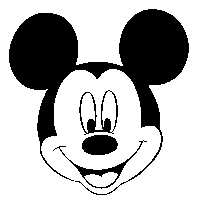

In [40]:
img1 = Image.open('miki.png').convert('L')
img1

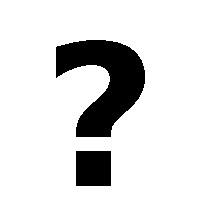

In [41]:
img2 = Image.open('quest.png').convert('L')
img2

Napisz funkcję **add_pic(img1, img2)**, która przyjmuje dwa obrazki i je dodaje piksel po pikselu za pomocą XOR, czyli **biały+biały=czarny, biały+czarny=biały, czarny+czarny=czarny**. Warto wykorzystać to, że **np.array(img)** zwraca tablicę, z wartościami 255 dla białych pikseli i 0 dla czarnych, aby zamienić tablicę z powrotem na obraz należy użyc **Image.fromarray()** przy czym tablica musi być typu **np.uint8** czyli tworząc tablicę podajemy typ: **np.array([1,2,3,4], dtype=np.uint8)**. Funkcja ma zwracać obrazek.

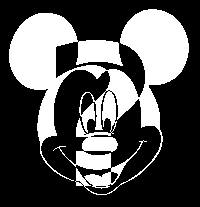

In [42]:
def add_pic(img1, img2):
    a = np.array(img1, dtype=np.uint8)
    b = np.array(img2, dtype=np.uint8)
    c = a ^ b
    return Image.fromarray(c)

add_pic(img1, img2)


Wygeneruj (pseudo)losowy klucz, czyli obrazek z losowymi białymi i czarnymi pikselami, użyj **np.random**. Następnie zaszyfruj tym kluczem, za pomocą **add_pic**, oba obrazki **img1** i **img2**. Zauważ, że oba obrazki wyglądają na dobrze zaszyfrowane, zobacz jednak co się wydarzy kiedy dodasz do siebie te zaszyfrowane obrazki.

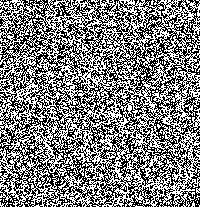

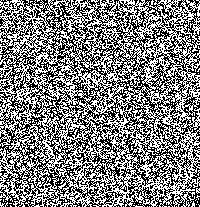

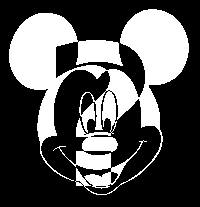

In [43]:
temp_array = np.array(img1.convert("L"), dtype=np.uint8)
rng = np.random.default_rng(42)
r = rng.integers(0, 2, size=temp_array.shape, dtype=np.uint8) * 255
r = Image.fromarray(r)

img1_encrypted = add_pic(img1, r)
img2_encrypted = add_pic(img2, r)

display(img1_encrypted)
display(img2_encrypted)
display(add_pic(img1_encrypted, img2_encrypted))


## Zadanie 4 (2 pkt.)

Zmienne ***msg1_enc*** oraz ***msg2_enc*** zawierają dwie zaszyfrowane wiadomości, w języku angielskim.

In [44]:
msg1_enc = '\x1e\x17\x0c\x12\x1b\x08\x0cf\x0e\x11x\x1a\x1c\x12o\x06\x18\x1f\x17\x03\x10\x01fkh\x1f\x08'
msg2_enc = '\x0b\ni\x07\x1c\x02k\x1f\x16e\x01\x0b\x07\x03\n\x15\x15\x0c\x1el\x07\x03\x03\x16\x01\x01\x02'

Wiadomo, że zostały zaszyfrowane tym samym kluczem, możemy to wykorzystać do odszyfrowania ich. W tym zadaniu konwencja zamiany liter na liczby i ich dodawania jest inna, niż w poprzednich. Znaki zamieniamy na liczby kodujące te znaki w **Unicode**, czyli za pomocą **ord()**, następnie dodajemy je do siebie za pomocą XOR na poziomie bitów, czyli za pomocą **^**. Napisz funkcję **add_str(msg1, msg2)**, które przyjmuje dwa teksty i zwraca tekst będący sumą tych tekstów zgodnie z powyższą konwencją.

In [45]:
def add_str(msg1, msg2):
    c = "".join(chr(ord(a) ^ ord(b)) for a, b in zip(msg1, msg2))
    return c

sum = add_str(msg1_enc, msg2_enc)
sum


'\x15\x1de\x15\x07\ngy\x18ty\x11\x1b\x11e\x13\r\x13\to\x17\x02e}i\x1e\n'

Zauważmy, że jeżeli dwie wiadomości są zaszyfrowane tym samym kluczem to dodanie ich do siebie sprawia, że dostaniemy sumę wiadomości bez klucza. Poza tym zauważmy, że jeżeli znamy jakieś słowo występujące w którejś z wiadomości i je dodamy do sumy tych wiadomości w odpowiednim miejscu to w wyniku dostaniemy poprawne słowo z drugiej wiadomości. Zatem metoda łamania tych wiadomości jest następująca, zgadujemy jakie słowo może być w którejś z wiadomości, dodajemy je w różnych miejscach sumy wiadomości i patrzymy czy powstaje coś co może być fragmentem poprawnego tekstu, następnie na podstawie tego fragmentu zgadujemy większą pozostałą część słowa i teraz to słowo używamy do odczytania kolejnego fragmentu z pierwszej wiadomości.

Pierwsze słowo wybieramy z pośród najpopularniejszych słów w danym języku.

Najpopularniejsze angielskie słowa:
1. THE
2. BE
3. TO
4. OF
5. AND

Uwaga 1: Słowa zapisane są drukowanymi literami.

Uwaga 2: Słowa oddzialane są spacjami, zatem biorąc np. słowo THE należy sprawdzać ciąg znaków "&nbsp; THE &nbsp;", ze spacjami na początku i końcu, dzięki temu odszyfrujemy więcej znaków.

In [46]:
def decode_str(sum, word):
    for i in range(0, len(sum) - len(word) + 1):
        print(add_str(sum[i:], word))

word1 = str(' THE ')
decode_str(sum, word1)


5I-P'
=1]B*
EAOOG
5SB"Y
'^/<8
*31]T
G-P1Y
YL<<1
8 1T;
T-Y^1
YESTE
1OY 3
;E-V-
11[H3
EGEV)
3Y[LO
-GA*7
3]'R"
);_GE
OCJ ]
7V-8I
"15,>
E)![*


In [47]:
word2 = str(' YESTERDAY ')
decode_str(sum, word2)


5D FSO5=Y-Y
=<PT^"+\5 1
ELBY3<J08H;
5^O4-]&=PB1
'S"*L1+UZHE
*><K <C_P<3
G ]'-TIU$J-
YA1*E^C!RT3
8-<BOT7WLJ)
T THE AIRPO
YH^B1V_WH67
1BT6GHAM.N"
;H @YV[+V[E
1<V^GL=SC<]
EJH@]*EF$$I
3TVZ;RP!<0>
-JL<CG79(G*


In [48]:
word3 = str('T THE AIRPORT ')
decode_str(sum, word3)

A=1]B*&0J$6CO1
IEAOOG8Q&)^IEE
15SB"YY=+ATC13
A'^/<850CK^7G-
S*31]T8XIA*AY3
^G-P1YPRC5\_G)
3YL<<1ZX7CBA]O
-8 1T;P,A]\[;7
LT-Y^1$Z_CF=C"
 YESTERDAY EVE
-1OY 3LZ[?XP1]
E;E-V-R@=GM7)I
O11[H3H&ER*/=>
EEGEV).^P52;J*


In [49]:
word4 = str('AND YESTERDAY EVENING')
decode_str(sum, word4)

TS!5^O4-]&=PB1 EH]@!P
\+Q'S"*L1+UZHEV[VG&YE
$[C*><K <C_P<3HEL!^L"
TING ]'-TIU$J-V_*YK+:
FD#YA1*E^C!RT3L9RL,3.
K)=8-<BOT7WLJ)*AG+4'Y
&7\T THE AIRPORT 3 PM


In [55]:
word45 = str(' AND ')
decode_str(sum, word45)

5\+Q'
=$[C*
ETING
5FD#Y
'K)=8
*&7\T
G8V0Y
YY:=1
857U;
T8__1
YPUUE
1Z_!3
;P+W-
1$]I3
ERCW)
3L]MO
-RG+7
3H!S"
).YFE
OVL!]
7C+9I
"$3->
E<'Z*


In [56]:
word5 = str("MEETING AT THE AIRPORT 3 PM")
decode_str(sum, word5)

XX AND YY YESTERDAY EVENING


In [51]:
word6 = str("XX AND YY YESTERDAY EVENING")
decode_str(sum, word6)

MEETING AT THE AIRPORT 3 PM


## Zadanie 5 (2 pkt.)

W poprzednim zadaniu korzystaliśmu z faktu, że obie wiadomości były zaszyfrowane przy użyciu tego samego klucza. Jednka w praktyce nie wiemy, które i czy w ogóle, wiadomosci były zaszyfrowane przy użyciu tego samego klucza. Możemy to wykryć dokonując analizy statystycznej. Załóżmy, że dodajemy do siebie dwie wiadomości zaszyfrowane tymi samymi kluczami. Wtedy miejsca w których dostaniemy 0 (w konwencji użytej w tym zadaniu znak odpowiadający 0 w Unicode, czyli chr(0)) są miejscami w których w obu wiadomościach była ta sama litera. Jeżeli natomiast dodajemy wiadomości o różnych kluczach będziemy dostawać 0 w losowych miejscach. Zatem w pierwszym przypadku otrzymamy więcej 0.

Zatem należy wczytać wszystkie wiadomości msg1.txt, msg2.txt itd. a następnie dodać je do siebie parami, każda z każdą i policzyć odsetek 0 (tzn. znaków chr(0)) w otrzymanych sumach. Para wiadomości o wyższym niż inne odsetku będzie tą zaszyfrowaną przy u życiu tego samego klucza. Aby łatwiej zauważyć taką parę warto zilustrować sobie wyniki (odsetki 0) za pomocą **plt.imshow(X ,norm=LogNorm())** i użyć skali logarytmicznej, gdzie **X** to tablica 10 na 10 zawierająca odsetki 0 dla każdej pary wiadomości.

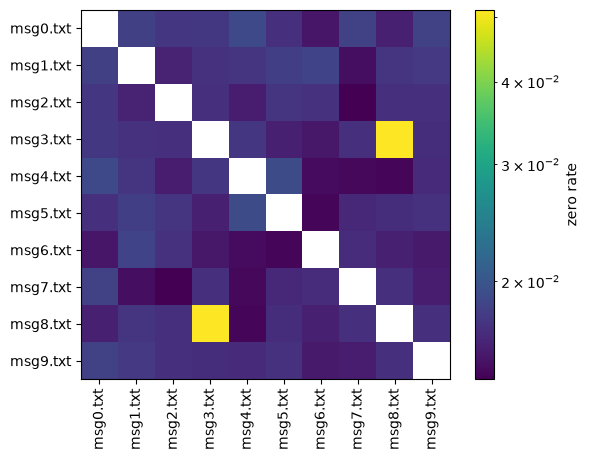

In [53]:
from itertools import combinations
from pathlib import Path
import matplotlib.pyplot as plt

messages = {p.name: p.read_text(encoding="utf8") for p in Path(".").glob("*.txt")}
names = list(messages)
n = len(names)
X = np.full((n, n), np.nan)

for (i, n1), (j, n2) in combinations(enumerate(names), 2):
    x = add_str(messages[n1], messages[n2])
    
    X[i, j] = X[j, i] = x.count(chr(0)) / len(x)

plt.imshow(X, norm=LogNorm())
plt.colorbar(label="zero rate")
plt.xticks(range(n), names, rotation=90)
plt.yticks(range(n), names)
plt.show()

In [54]:
suma = add_str(messages["msg3.txt"], messages["msg8.txt"])

def show(s):
    return "".join(ch if ch.isprintable() else "." for ch in s)


def slide(c, word):
    for i in range(len(word)):
        rot = word[i:] + word[:i]
        mask = (rot * (len(c) // len(rot) + 1))[:len(c)]
        print(f"phase {i}: {show((add_str(c, mask))[:300])}")
word1 = (" TAK ")
slide(suma, word1)

phase 0: 5_..Ĉ...6EĵLű.u1GC[;3űV.s'Ĥ.G cDJJn6űA.; WOL-Œġ. ..RVUc?ARžoł5@At.ŽĹ.c4.TV>7ſ.[ĊłUP.n>.\Ľb3..DĹ LCA=rY]V=ŀ.Aĩ.dIU.Ča.DW?...r*n;&Fz.I[Wąz\.I &.FUŜm.\.Ŗ=^Ĺ.# Z.x$sRZ.O.kŰH!g.[Q5+A.A,oUK\k"Fź.9 PLK.(TĭK.%.TUŔ Ŧ.X$ Gġĩj'ťTI,ć.*&Ĉ KZ\;<..K$óPIŤ z.Ŝľeį.GO9y.MJ(ā..Ył&R.K%.WT.5....7,@.\.;P.AŃŞTA_0u..f((O.Xt
phase 1: AJ.iĈZ..]EŁYŻvuERI0;GŤ\esSı., .Q@!nBŤKw;TBE'-ĦĴ.K.`G\>cKTXĕoĶ J*tZŨĳhc@.^=>CŪ.0ĊĶ@ZanJ.VŖbG../ĹTYI*=.LW==Ĵ.Kł..\_rČ..N<?Z...*..,-z{\Q<ą.I." R.L>Ŝ..VzŖIKĳn#TO..$.GPgO~~ź#!..Q:5_T.*,.@A7kVSŰo9TEF .\Aħ .Q.^>ŔTų.3$TRīłjSŰ^",ų. MĈT^P7;H.. $.ECď ..Ŗŕeś.M$9..G!(ŵ..2łRG. %ZB^{5Z..r7XU.7.OE.*ŃĪAK40....(\Z.3t
phase 2: T@liżO.o]1ŔSĐv.PX"0ORŮ7e.FĻe,T.[+!.WŮ wOAH.'YĳľmK~uM7>.^^3ĕ.ģ*!*.OŢŘh.U.5=JVŠó0žģJ1a._.=Ŗ.R.s/ōAS"*I.F<=Iġ. łZ.V4rŸ..%<KO.n.^.$G-.nV:<ű.Cb"TG.'>Ĩ..=zĢ\AŘnWAEp.P.M;g;ktđ#U..::AJ^k*X.J*7.CYěoMAO- ZIKŌ rD.5>ĠAŹw3PAXŀł.Fź5"XŦ.KMżAT;7O].l P.O(ďT..Ľŕ.Ŏ.&$M..,!\Š.j2ĶGMw QOH5{AO.|rCM_i7ZZOs*ķĿK 4D..o.\IPo3.
phase 3: ^+l.ũEto)$Ş8Đ..Z3"DZXą7..LŐeXA.0+U.]ą .ZK#.SLĹŕm?k.&7J.T53š.ĩ